# Predicting next-day market direction with PyTorch

Goal: given what we know at today's close, predict whether the **S&P 500** (`^GSPC`) closes **up or down tomorrow**.
Then check the same model on the **NASDAQ-100** (`^NDX`).

Each step = an idea + a plot. Run top to bottom.

Spoiler: markets are close to a coin flip day to day. Expect ~50-55% accuracy. The point is learning the workflow
(data, features, honest splits, baselines, training loop, evaluation), not getting rich.

## Step 0. Setup

In [1]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yfinance as yf
from torch import nn

torch.manual_seed(42)
np.random.seed(42)

device = "mps" if torch.backends.mps.is_available() else "cpu"  # mps = Apple Silicon GPU
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
plt.rcParams["figure.figsize"] = (12, 4)
print("device:", device)

device: mps


## Step 1. Get the data

`yfinance` downloads daily OHLCV (open, high, low, close, volume) from Yahoo Finance.
We cache it to CSV so re-running the notebook does not hit the network (delete `data/` to refresh).

In [2]:
TICKERS = {"sp500": "^GSPC", "nasdaq100": "^NDX"}


def load(name, ticker):
    path = DATA_DIR / f"{name}.csv"
    if not path.exists():
        df = yf.download(ticker, start="2000-01-01", auto_adjust=True, progress=False)
        df.columns = df.columns.get_level_values(0)  # yfinance returns (field, ticker) columns
        df.to_csv(path)
    return pd.read_csv(path, index_col="Date", parse_dates=True)


prices = {name: load(name, ticker) for name, ticker in TICKERS.items()}
sp = prices["sp500"]
sp.tail()

,Close,High,Low,Open,Volume
Date,,,,,
2026-11-02,7541.399902,7662.229980,7539.379883,7610.830078,5712790000
2026-11-03,7568.919922,7594.609863,7545.390137,7552.919922,5481240000
2026-11-04,7688.620117,7715.569824,7635.810059,7635.810059,7390830000
2026-11-05,7353.729980,7681.290039,7350.350098,7678.720215,7654840000
2026-11-06,7376.859863,7444.200195,7369.549805,7377.649902,5701900000


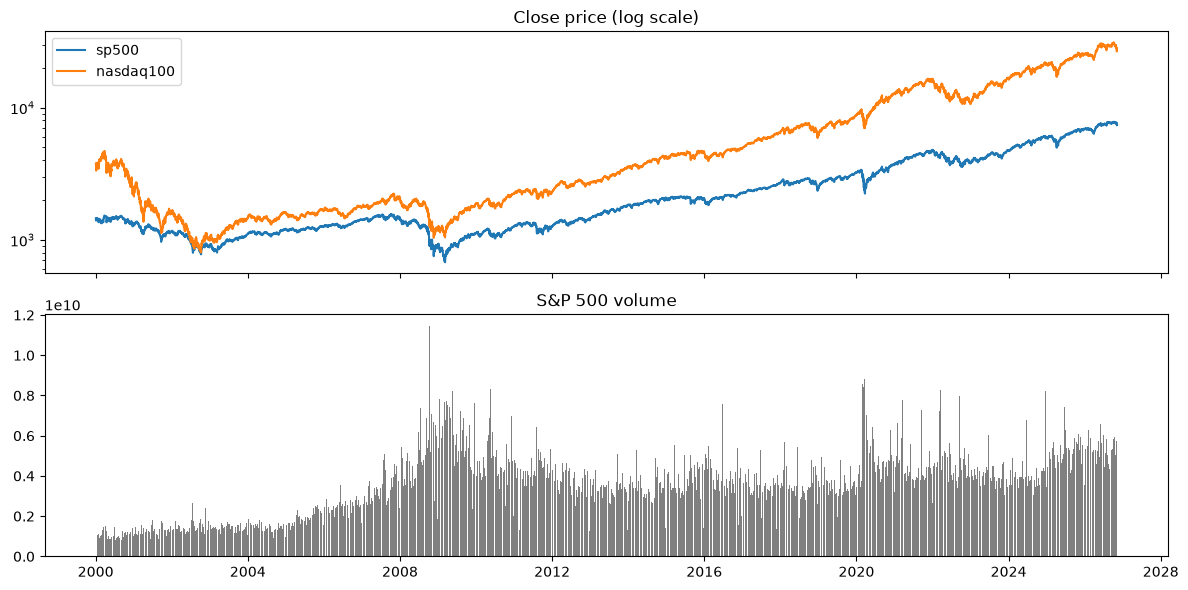

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for name, df in prices.items():
    ax1.plot(df.index, df["Close"], label=name)
ax1.set_yscale("log")  # log scale: equal vertical distance = equal % move
ax1.set_title("Close price (log scale)")
ax1.legend()
ax2.bar(sp.index, sp["Volume"], width=2, color="gray")
ax2.set_title("S&P 500 volume")
plt.tight_layout()

## Step 2. Explore: prices vs returns

Prices trend upward forever, so a model trained on 2005 prices (~1200) has never seen 2025 prices (~6000).
**Returns** (daily % change) live on the same scale in every era, which is what a model needs.

Three things to notice in the plots below:
1. **Volatility clusters**: calm periods and stormy periods (2008, 2020, 2022).
2. **Fat tails**: big moves happen far more often than a normal (bell) curve predicts.
3. **Almost no autocorrelation**: yesterday's return barely tells you today's. That is why this problem is hard.
   But the *size* of moves (|return|) is strongly autocorrelated: volatility is predictable, direction mostly is not.

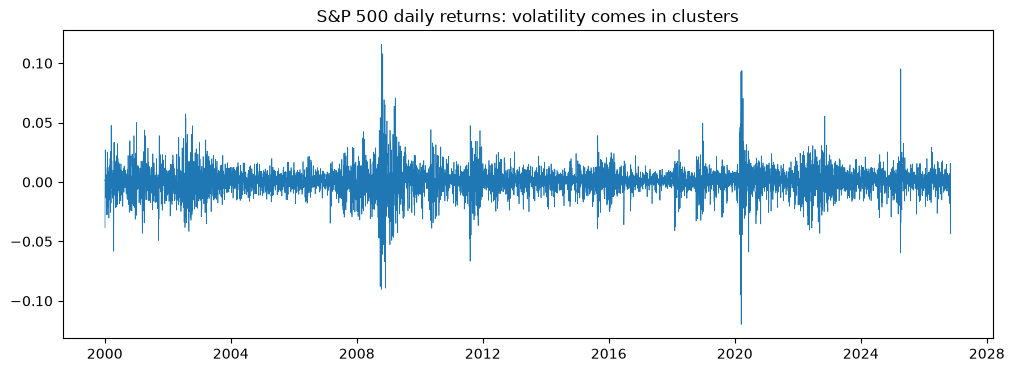

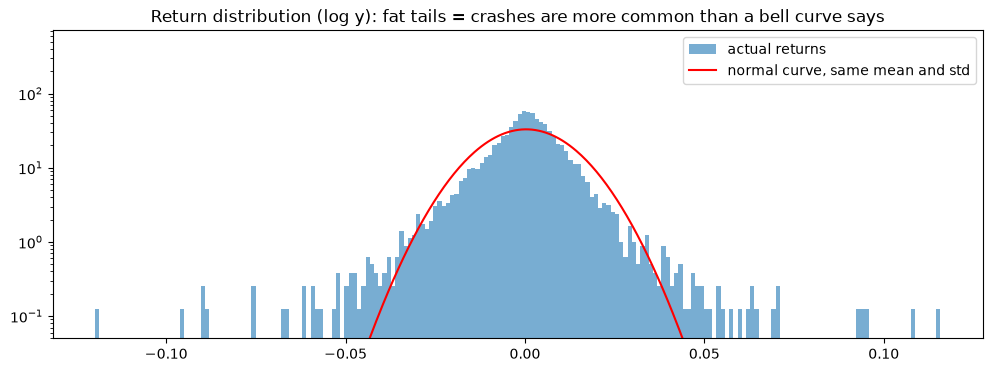

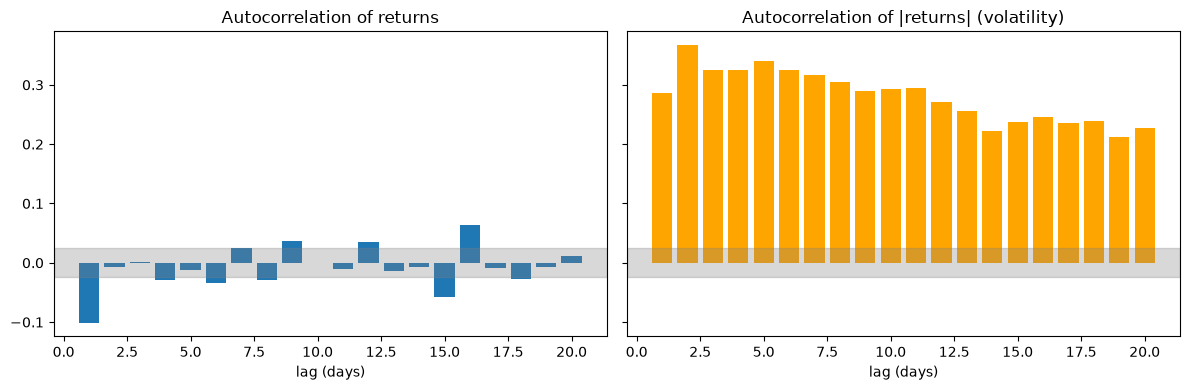

In [4]:
ret = sp["Close"].pct_change().dropna()

fig, ax = plt.subplots()
ax.plot(ret.index, ret, lw=0.5)
ax.set_title("S&P 500 daily returns: volatility comes in clusters")
plt.show()

fig, ax = plt.subplots()
ax.hist(ret, bins=200, density=True, alpha=0.6, label="actual returns")
x = np.linspace(ret.min(), ret.max(), 500)
normal_pdf = np.exp(-((x - ret.mean()) ** 2) / (2 * ret.var())) / np.sqrt(2 * np.pi * ret.var())
ax.plot(x, normal_pdf, "r", label="normal curve, same mean and std")
ax.set_yscale("log")
ax.set_ylim(bottom=0.05)  # a single day in a bin is ~0.1; below that the normal curve just dives to 0
ax.set_title("Return distribution (log y): fat tails = crashes are more common than a bell curve says")
ax.legend()
plt.show()

lags = range(1, 21)
band = 2 / np.sqrt(len(ret))  # roughly: bars inside the band are indistinguishable from noise
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax1.bar(lags, [ret.autocorr(lag) for lag in lags])
ax1.set_title("Autocorrelation of returns")
ax2.bar(lags, [ret.abs().autocorr(lag) for lag in lags], color="orange")
ax2.set_title("Autocorrelation of |returns| (volatility)")
for ax in (ax1, ax2):
    ax.axhspan(-band, band, color="gray", alpha=0.3)
    ax.set_xlabel("lag (days)")
plt.tight_layout()

## Step 3. Features and target

Each row = one trading day *t*. Features use only information known at day *t*'s close:

- `ret_0 ... ret_9`: returns of the last 10 days (`ret_0` = today)
- `vol_20`: standard deviation of the last 20 returns (how stormy it is)
- `ma_dist_50`, `ma_dist_200`: how far price is above/below its 50 and 200 day average (trend)

**Target**: `1` if day *t+1* closes up, else `0`. We also keep `next_ret` (tomorrow's actual return) for the backtest.

`shift(k)` moves a column k rows down (looks into the past); `shift(-1)` looks one day into the future, which is
allowed **only** for the target.

In [5]:
N_LAGS = 10


def make_features(close):
    ret = close.pct_change()
    f = pd.DataFrame(index=close.index)
    for lag in range(N_LAGS):
        f[f"ret_{lag}"] = ret.shift(lag)
    f["vol_20"] = ret.rolling(20).std()
    f["ma_dist_50"] = close / close.rolling(50).mean() - 1
    f["ma_dist_200"] = close / close.rolling(200).mean() - 1
    f["next_ret"] = ret.shift(-1)
    f["target"] = (f["next_ret"] > 0).astype(int)
    return f.dropna()  # drops the first 200 days (no 200-day average yet) and the last day (no tomorrow)


feats = make_features(sp["Close"])
FEATURES = [c for c in feats.columns if c not in ("next_ret", "target")]
feats.tail()

,ret_0,ret_1,ret_2,ret_3,ret_4,ret_5,ret_6,ret_7,ret_8,ret_9,vol_20,ma_dist_50,ma_dist_200,next_ret,target
Date,,,,,,,,,,,,,,,
2026-10-30,-0.018175,-0.003046,0.002768,0.005970,0.006964,-0.005187,-0.012084,0.005783,0.002840,0.004085,0.007394,-0.015202,0.036980,-0.005102,0
2026-11-02,-0.005102,-0.018175,-0.003046,0.002768,0.005970,0.006964,-0.005187,-0.012084,0.005783,0.002840,0.007228,-0.019887,0.031268,0.003649,1
2026-11-03,0.003649,-0.005102,-0.018175,-0.003046,0.002768,0.005970,0.006964,-0.005187,-0.012084,0.005783,0.007130,-0.016096,0.034587,0.015815,1
2026-11-04,0.015815,0.003649,-0.005102,-0.018175,-0.003046,0.002768,0.005970,0.006964,-0.005187,-0.012084,0.008119,-0.000565,0.050308,-0.043557,0
2026-11-05,-0.043557,0.015815,0.003649,-0.005102,-0.018175,-0.003046,0.002768,0.005970,0.006964,-0.005187,0.012561,-0.043297,0.004233,0.003145,1


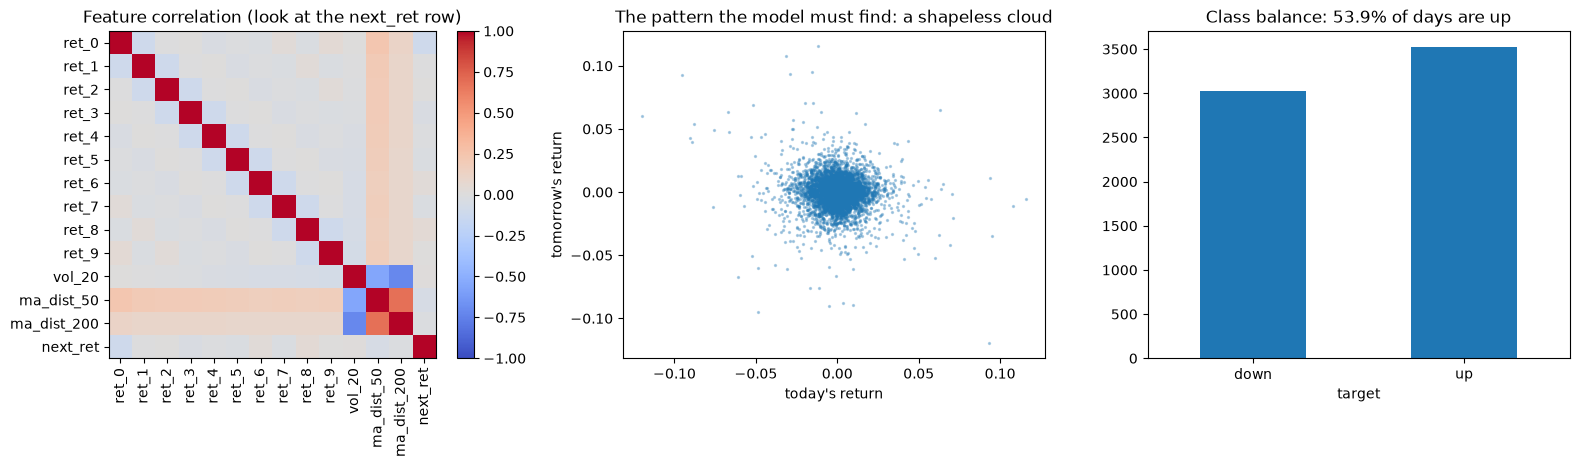

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

corr = feats[FEATURES + ["next_ret"]].corr()
im = axes[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(corr)), corr.columns, rotation=90)
axes[0].set_yticks(range(len(corr)), corr.columns)
axes[0].set_title("Feature correlation (look at the next_ret row)")
fig.colorbar(im, ax=axes[0])

axes[1].scatter(feats["ret_0"], feats["next_ret"], s=2, alpha=0.3)
axes[1].set_xlabel("today's return")
axes[1].set_ylabel("tomorrow's return")
axes[1].set_title("The pattern the model must find: a shapeless cloud")

feats["target"].value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set_xticks([0, 1], ["down", "up"], rotation=0)
axes[2].set_title(f"Class balance: {feats['target'].mean():.1%} of days are up")
plt.tight_layout()

## Step 4. Split by time (never shuffle)

- **train** 2000-2018: the model learns from this
- **validation** 2019-2021: we tune and pick the best epoch on this
- **test** 2022-today: touched once, at the end, for the final honest score

With time series, a random split leaks the future: the model would train on 2023 and be "tested" on 2022.
Same rule for scaling: mean and std come from **train only**, otherwise test statistics leak into training.

Scaling (z-score: subtract mean, divide by std) puts every feature around 0 with spread 1, so no feature
dominates just because its numbers are bigger.

In [7]:
train, val, test = feats[:"2018"], feats["2019":"2021"], feats["2022":]
mean, std = train[FEATURES].mean(), train[FEATURES].std()


def to_tensors(df):
    X = torch.tensor(((df[FEATURES] - mean) / std).values, dtype=torch.float32)
    y = torch.tensor(df["target"].values, dtype=torch.float32).unsqueeze(1)  # shape (n, 1) to match model output
    return X.to(device), y.to(device)


X_train, y_train = to_tensors(train)
X_val, y_val = to_tensors(val)
X_test, y_test = to_tensors(test)
print({name: len(df) for name, df in [("train", train), ("val", val), ("test", test)]})
print("X_train shape:", tuple(X_train.shape), "= (days, features)")

{'train': 4580, 'val': 757, 'test': 1216}
X_train shape: (4580, 13) = (days, features)


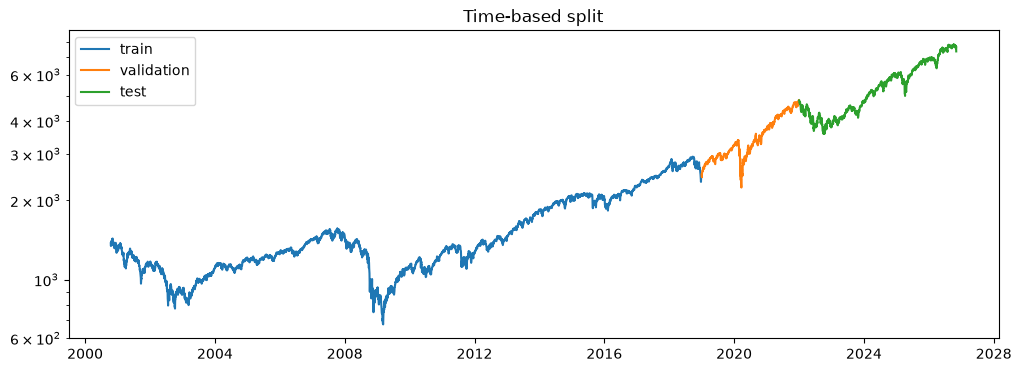

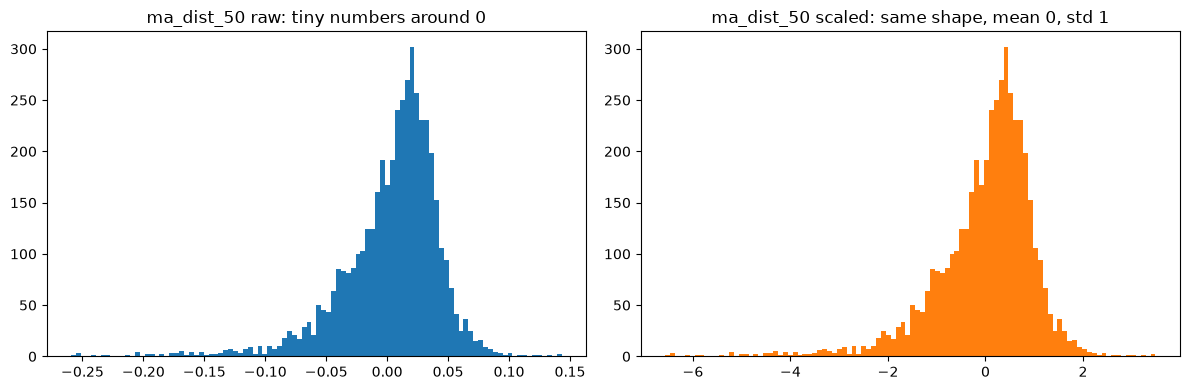

In [8]:
fig, ax = plt.subplots()
for name, df, color in [("train", train, "C0"), ("validation", val, "C1"), ("test", test, "C2")]:
    ax.plot(df.index, sp.loc[df.index, "Close"], color=color, label=name)
ax.set_yscale("log")
ax.set_title("Time-based split")
ax.legend()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(train["ma_dist_50"], bins=100)
ax1.set_title("ma_dist_50 raw: tiny numbers around 0")
ax2.hist(X_train[:, FEATURES.index("ma_dist_50")].cpu().numpy(), bins=100, color="C1")
ax2.set_title("ma_dist_50 scaled: same shape, mean 0, std 1")
plt.tight_layout()

## Step 5. Baselines: the scores to beat

A model is only interesting if it beats dumb rules:

1. **Always up**: markets rise slightly more often than they fall.
2. **Same as today**: predict tomorrow moves in today's direction (momentum).
3. **Logistic regression**: a neural network with **zero hidden layers**: `probability = sigmoid(w . x + b)`.

The training loop below is the heart of PyTorch, and every model in this notebook reuses it:

1. **forward**: model turns inputs into a *logit* (any real number; `sigmoid(logit)` = probability of "up")
2. **loss**: `BCEWithLogitsLoss` (binary cross-entropy) punishes confident wrong answers hard
3. **backward**: `loss.backward()` computes the gradient (which direction to nudge each weight to reduce loss)
4. **step**: the optimizer (Adam) nudges the weights; `zero_grad()` clears old gradients first

One pass over the training data = one **epoch**, done in shuffled mini-batches (shuffling rows *inside* train is
fine: each row already carries its own past). After each epoch we measure validation loss and keep the weights
from the best epoch (**early stopping**).

In [9]:
def train_model(model, X_tr, y_tr, X_va, y_va, epochs=100, lr=1e-3, weight_decay=0.0, batch_size=256):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_loss, best_state = float("inf"), None

    for _ in range(epochs):
        model.train()  # enables dropout
        perm = torch.randperm(len(X_tr)).to(device)
        for i in range(0, len(X_tr), batch_size):
            idx = perm[i : i + batch_size]
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])  # 1. forward + 2. loss
            optimizer.zero_grad()
            loss.backward()  # 3. gradients
            optimizer.step()  # 4. update weights

        model.eval()  # disables dropout
        with torch.no_grad():  # no gradients needed for measuring
            val_logits = model(X_va)
            history["train_loss"].append(loss_fn(model(X_tr), y_tr).item())
            history["val_loss"].append(loss_fn(val_logits, y_va).item())
            history["val_acc"].append(((val_logits > 0).float() == y_va).float().mean().item())
        if history["val_loss"][-1] < best_loss:
            best_loss, best_state = history["val_loss"][-1], copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return history


def plot_history(history, title):
    best = int(np.argmin(history["val_loss"]))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history["train_loss"], label="train")
    ax1.plot(history["val_loss"], label="validation")
    ax1.axvline(best, color="gray", ls="--", label=f"best epoch ({best})")
    ax1.set_title(f"{title}: loss")
    ax1.set_xlabel("epoch")
    ax1.legend()
    ax2.plot(history["val_acc"], color="C1")
    ax2.axhline(0.5, color="gray", ls=":")
    ax2.set_title(f"{title}: validation accuracy")
    ax2.set_xlabel("epoch")
    plt.tight_layout()
    plt.show()


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(X)).squeeze(1).cpu().numpy()

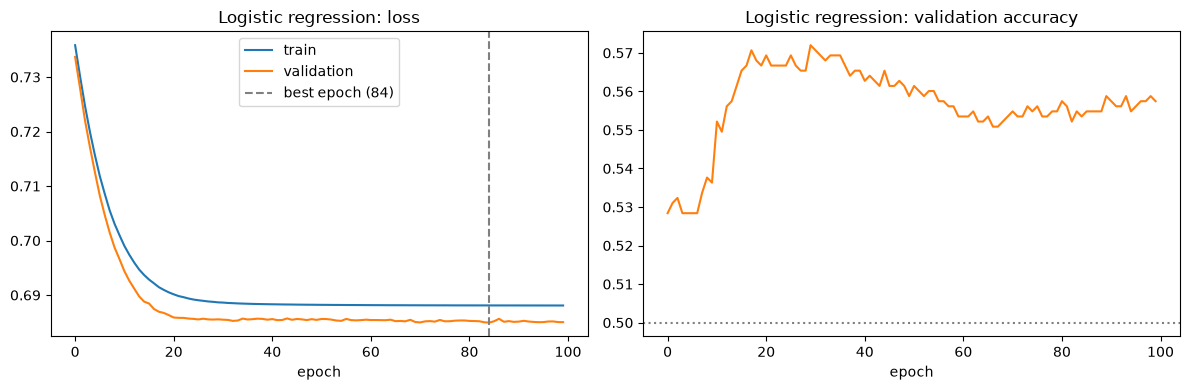

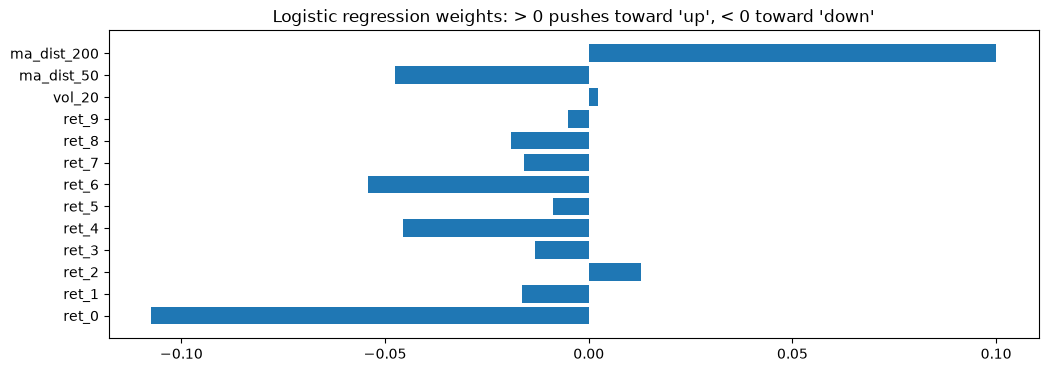

In [10]:
logreg = nn.Linear(len(FEATURES), 1)  # zero hidden layers
logreg_history = train_model(logreg, X_train, y_train, X_val, y_val, epochs=100)
plot_history(logreg_history, "Logistic regression")

fig, ax = plt.subplots()
ax.barh(FEATURES, logreg.weight.detach().cpu().squeeze().numpy())
ax.set_title("Logistic regression weights: > 0 pushes toward 'up', < 0 toward 'down'")
plt.show()

## Step 6. A real neural network (MLP)

A multi-layer perceptron stacks `Linear -> ReLU` layers. ReLU (`max(0, x)`) bends the straight lines of logistic
regression so the network can learn curved, interacting patterns (e.g. "big drop **and** high volatility").
`Dropout` randomly zeroes 20% of neurons during training so the network cannot memorise; `weight_decay`
keeps weights small. Both fight **overfitting**.

First, one training step by hand, to see every piece:

In [11]:
mlp = nn.Sequential(
    nn.Linear(len(FEATURES), 64), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(32, 1),
).to(device)
print(mlp)
print("trainable parameters:", sum(p.numel() for p in mlp.parameters()))

xb, yb = X_train[:5], y_train[:5]
logits = mlp(xb)
loss = nn.BCEWithLogitsLoss()(logits, yb)
print("\nlogits:        ", logits.squeeze().tolist())
print("probabilities: ", torch.sigmoid(logits).squeeze().tolist(), "(untrained: all near 0.5)")
print("true labels:   ", yb.squeeze().tolist())
print("loss:          ", loss.item(), "(ln 2 = 0.693 = coin flip)")

loss.backward()
grad = mlp[0].weight.grad
print("\nfirst layer gradient shape:", tuple(grad.shape), "= one number per weight")
print("gradient norm:", grad.norm().item())
mlp.zero_grad()

Sequential(
  (0): Linear(in_features=13, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=32, out_features=1, bias=True)
)
trainable parameters: 3009

logits:         [-0.08359167724847794, -0.055814653635025024, -0.1309182494878769, -0.008138224482536316, -0.09553484618663788]
probabilities:  [0.47911423444747925, 0.48604995012283325, 0.467317134141922, 0.49796542525291443, 0.47613444924354553] (untrained: all near 0.5)
true labels:    [0.0, 0.0, 1.0, 1.0, 0.0]
loss:           0.6844691038131714 (ln 2 = 0.693 = coin flip)

first layer gradient shape: (64, 13) = one number per weight
gradient norm: 0.21297955513000488


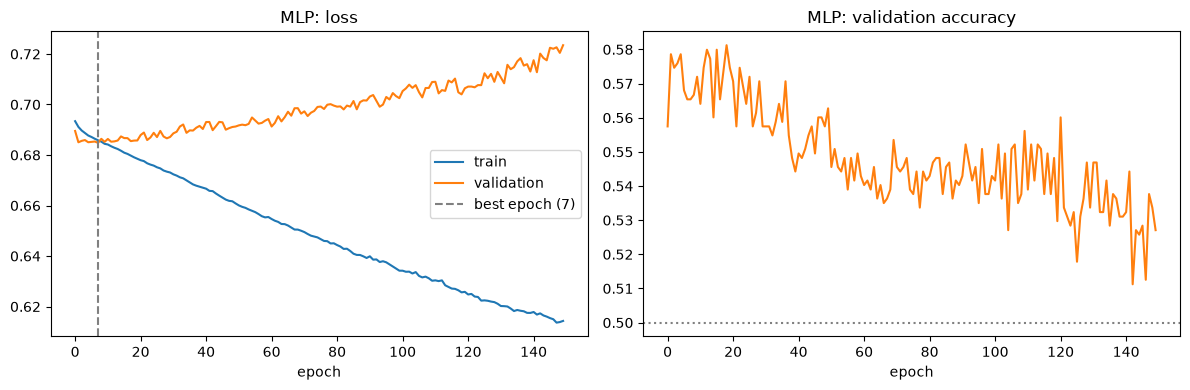

In [12]:
mlp_history = train_model(mlp, X_train, y_train, X_val, y_val, epochs=150, weight_decay=1e-4)
plot_history(mlp_history, "MLP")

Train loss keeps falling while validation loss flattens or rises: the network is starting to memorise the past
instead of learning something that carries over. The dashed line is the epoch we keep.

## Step 7. Honest evaluation on the test set (2022-today)

Now, once, we touch the test set. Three views:

1. **Accuracy vs baselines**
2. **Confusion matrix**: of the days the model said "up", how many went up?
3. **Predicted probabilities**: a confident model spreads out; an unsure one piles up near 0.5
4. **Toy backtest**: hold the index on days the model says "up", sit in cash otherwise. Compared with buy and hold.
   No trading costs, slippage or taxes, so real results would be worse.

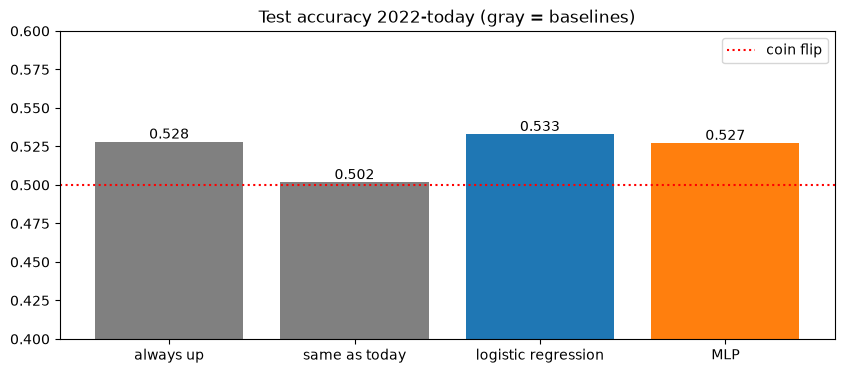

In [13]:
test_preds = {
    "always up": np.ones(len(test), dtype=int),
    "same as today": (test["ret_0"] > 0).astype(int).values,
    "logistic regression": (predict_proba(logreg, X_test) > 0.5).astype(int),
    "MLP": (predict_proba(mlp, X_test) > 0.5).astype(int),
}


def plot_accuracy(preds, y_true, title):
    acc = {name: (p == y_true).mean() for name, p in preds.items()}
    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.bar(acc.keys(), acc.values(), color=["gray", "gray"] + [f"C{i}" for i in range(len(acc) - 2)])
    ax.bar_label(bars, fmt="%.3f")
    ax.axhline(0.5, color="red", ls=":", label="coin flip")
    ax.set_ylim(0.4, 0.6)
    ax.set_title(title)
    ax.legend()
    plt.show()


plot_accuracy(test_preds, test["target"].values, "Test accuracy 2022-today (gray = baselines)")

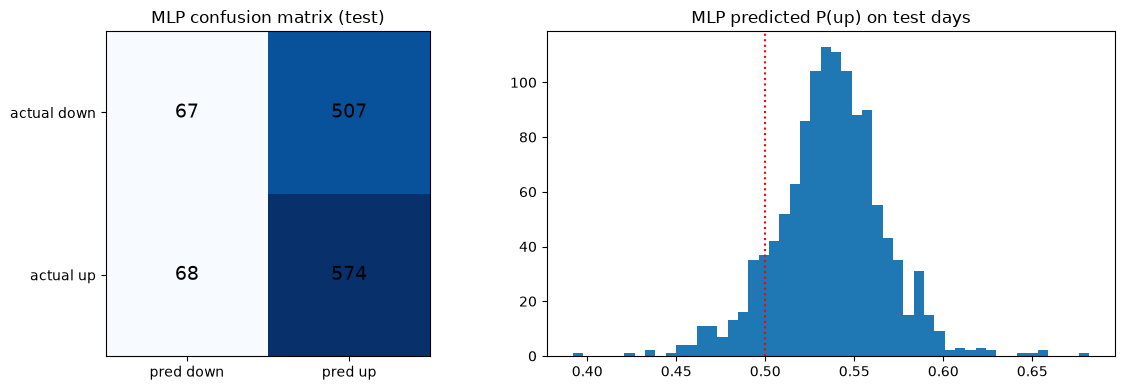

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
cm = pd.crosstab(test["target"].values, test_preds["MLP"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
ax1.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm.values):
    ax1.text(j, i, v, ha="center", va="center", fontsize=14)
ax1.set_xticks([0, 1], ["pred down", "pred up"])
ax1.set_yticks([0, 1], ["actual down", "actual up"])
ax1.set_title("MLP confusion matrix (test)")

ax2.hist(predict_proba(mlp, X_test), bins=50)
ax2.axvline(0.5, color="red", ls=":")
ax2.set_title("MLP predicted P(up) on test days")
plt.tight_layout()

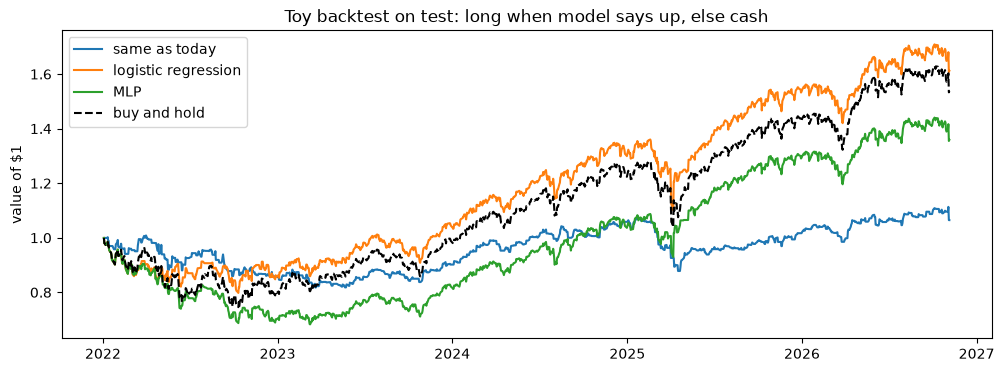

In [15]:
def plot_equity(preds, next_ret, index, title):
    fig, ax = plt.subplots()
    for name, p in preds.items():
        if name != "always up":  # identical to buy and hold
            ax.plot(index, (1 + p * next_ret).cumprod(), label=name)
    # drawn last and dashed: a model that (almost) always says "up" sits right under this line
    ax.plot(index, (1 + next_ret).cumprod(), color="black", ls="--", lw=1.5, label="buy and hold")
    ax.set_title(title)
    ax.set_ylabel("value of $1")
    ax.legend()
    plt.show()


plot_equity(test_preds, test["next_ret"].values, test.index, "Toy backtest on test: long when model says up, else cash")

## Step 8. Sequence models: let the network read the raw history

Instead of hand-made features, feed the last 60 daily returns directly and let the network find its own features.

- **LSTM** reads the 60 days one by one, carrying a memory (hidden state) forward, and predicts from its final state.
- **1D CNN** slides small filters (5 days wide) along the series, like a pattern detector, then pools them.

`sliding_window_view` turns the return series into overlapping windows: row *t* = returns of days *t-59 ... t*,
target = direction of day *t+1*.

window tensors: (4719, 60) = (days, 60 returns)


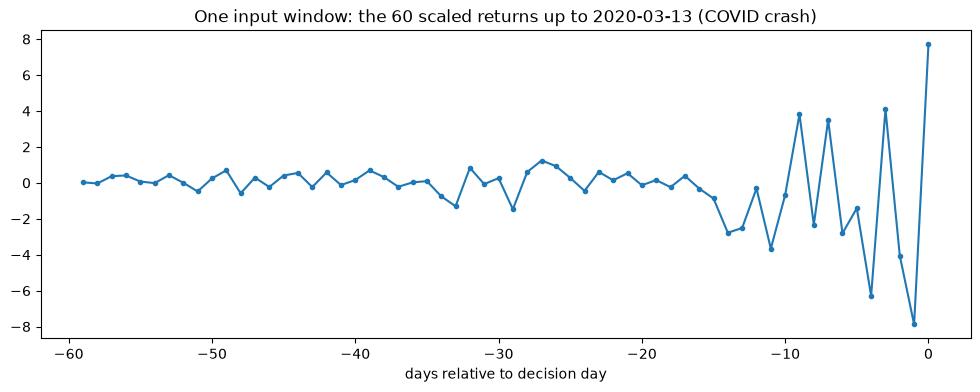

In [16]:
WINDOW = 60


def make_windows(close, ret_std):
    ret = close.pct_change().dropna()
    windows = np.lib.stride_tricks.sliding_window_view((ret / ret_std).values, WINDOW)[:-1]  # last window has no tomorrow
    next_ret = ret.values[WINDOW:]
    index = ret.index[WINDOW - 1 : -1]  # the decision day t = last day inside each window
    return pd.DataFrame(windows, index=index), pd.Series(next_ret, index=index)


sp_ret_std = sp["Close"].pct_change()[:"2018"].std()  # scale with train-period std only
win, win_next = make_windows(sp["Close"], sp_ret_std)


def window_tensors(start, end):
    X = torch.tensor(win[start:end].values, dtype=torch.float32)
    y = torch.tensor((win_next[start:end].values > 0), dtype=torch.float32).unsqueeze(1)
    return X.to(device), y.to(device)


Xw_train, yw_train = window_tensors(None, "2018")
Xw_val, yw_val = window_tensors("2019", "2021")
Xw_test, yw_test = window_tensors("2022", None)
print("window tensors:", tuple(Xw_train.shape), "= (days, 60 returns)")

fig, ax = plt.subplots()
ax.plot(range(-WINDOW + 1, 1), win.loc["2020-03-13"].values, marker=".")
ax.set_title("One input window: the 60 scaled returns up to 2020-03-13 (COVID crash)")
ax.set_xlabel("days relative to decision day")
plt.show()

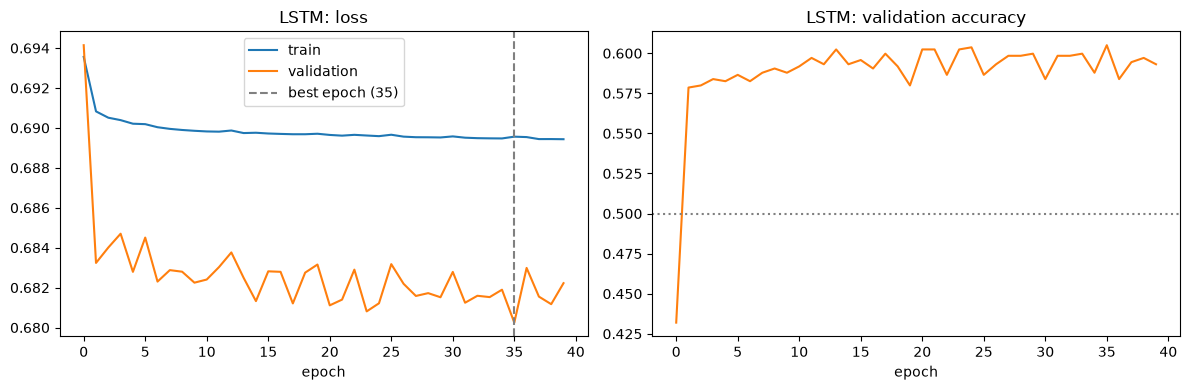

In [17]:
class LSTMNet(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):  # x: (batch, 60)
        out, _ = self.lstm(x.unsqueeze(-1))  # (batch, 60, 1): one feature per time step
        return self.head(out[:, -1])  # predict from the last time step's hidden state


lstm = LSTMNet()
lstm_history = train_model(lstm, Xw_train, yw_train, Xw_val, yw_val, epochs=40, weight_decay=1e-4)
plot_history(lstm_history, "LSTM")

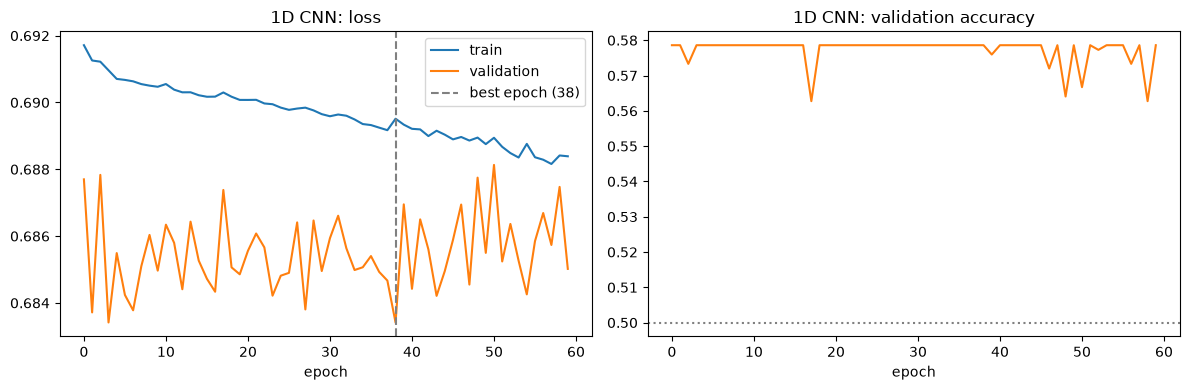

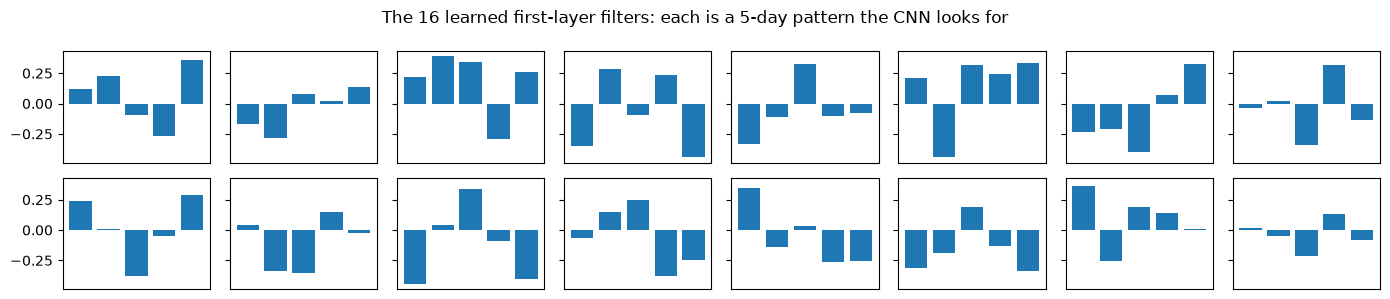

In [18]:
cnn = nn.Sequential(
    nn.Unflatten(1, (1, WINDOW)),  # (batch, 60) -> (batch, 1 channel, 60)
    nn.Conv1d(1, 16, kernel_size=5), nn.ReLU(), nn.MaxPool1d(2),
    nn.Conv1d(16, 32, kernel_size=5), nn.ReLU(),
    nn.AdaptiveAvgPool1d(1), nn.Flatten(),  # average each filter over time -> (batch, 32)
    nn.Dropout(0.2), nn.Linear(32, 1),
)
cnn_history = train_model(cnn, Xw_train, yw_train, Xw_val, yw_val, epochs=60, weight_decay=1e-4)
plot_history(cnn_history, "1D CNN")

filters = cnn[1].weight.detach().cpu().squeeze(1).numpy()  # (16 filters, 5 days)
fig, axes = plt.subplots(2, 8, figsize=(14, 3), sharey=True)
for f, ax in zip(filters, axes.flat):
    ax.bar(range(5), f)
    ax.set_xticks([])
fig.suptitle("The 16 learned first-layer filters: each is a 5-day pattern the CNN looks for")
plt.tight_layout()

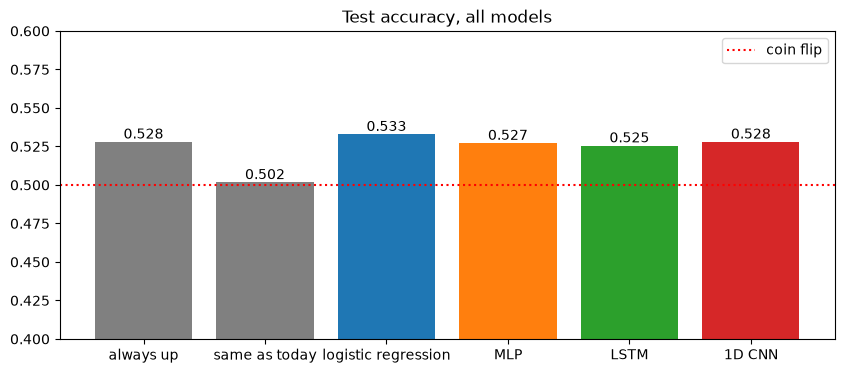

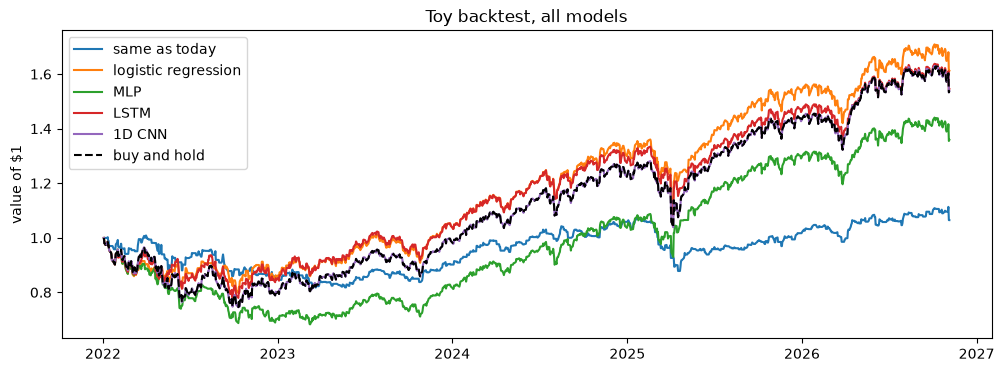

In [19]:
# Window test set starts at the same date as the feature test set; align both on common days.
common = test.index.intersection(win_next["2022":].index)
win_test_pos = win_next["2022":].index.get_indexer(common)
feat_test_pos = test.index.get_indexer(common)

all_preds = {name: p[feat_test_pos] for name, p in test_preds.items()}
all_preds["LSTM"] = (predict_proba(lstm, Xw_test) > 0.5).astype(int)[win_test_pos]
all_preds["1D CNN"] = (predict_proba(cnn, Xw_test) > 0.5).astype(int)[win_test_pos]

y_common = test.loc[common, "target"].values
plot_accuracy(all_preds, y_common, "Test accuracy, all models")
plot_equity(all_preds, test.loc[common, "next_ret"].values, common, "Toy backtest, all models")

## Step 9. Does it generalise? Train on S&P 500, test on NASDAQ-100

If the MLP learned something real about market behaviour, it should transfer to a related index it never saw.
We build NASDAQ-100 features the same way and scale them with the **S&P 500 training** mean and std
(the model's view of "normal").

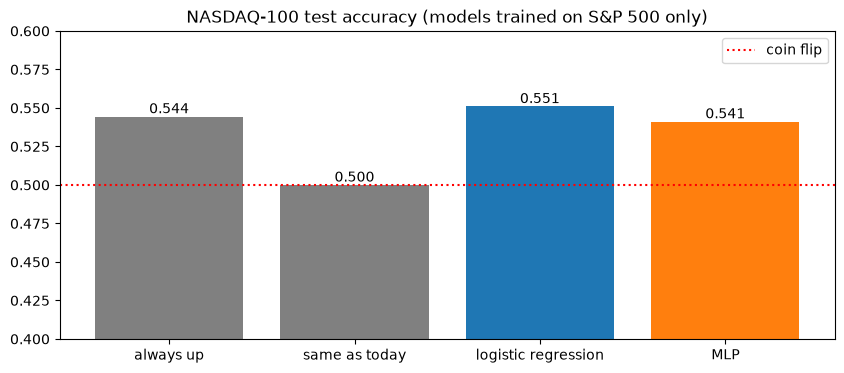

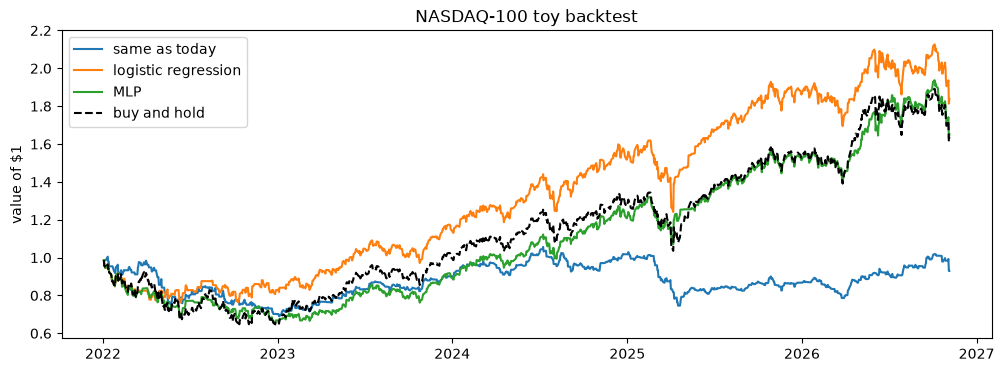

In [20]:
ndx = make_features(prices["nasdaq100"]["Close"])["2022":]
X_ndx, _ = to_tensors(ndx)
ndx_preds = {
    "always up": np.ones(len(ndx), dtype=int),
    "same as today": (ndx["ret_0"] > 0).astype(int).values,
    "logistic regression": (predict_proba(logreg, X_ndx) > 0.5).astype(int),
    "MLP": (predict_proba(mlp, X_ndx) > 0.5).astype(int),
}
plot_accuracy(ndx_preds, ndx["target"].values, "NASDAQ-100 test accuracy (models trained on S&P 500 only)")
plot_equity(ndx_preds, ndx["next_ret"].values, ndx.index, "NASDAQ-100 toy backtest")

## Takeaways

- The workflow is the same for any tabular or time-series problem: features -> time split -> scale on train ->
  baselines -> train loop -> early stopping -> one honest test.
- Daily direction is nearly unpredictable; "always up" is a strong baseline. Check the probability histogram and
  the backtest: a model whose line hugs buy and hold has mostly learned "say up", the safest bet it could find. A result far above ~55% here almost
  always means a leak (future data sneaking into features or scaling), not genius.
- Volatility *is* predictable (step 2). A natural next experiment: predict tomorrow's |return| (regression,
  `MSELoss`) instead of direction, and compare against "tomorrow = average of the last 20 days".